# Tutorial: Spatial Grids in Soft Potato (`ExponentialMesh` vs. `Uniform1DMesh`)

In electrochemical simulations, electron transfer occurs at the electrode surface ($x = 0$), creating steep concentration gradients within a thin diffusion boundary layer while the bulk solution remains nearly uniform. Discretizing space with a uniform grid often requires a large number of points to resolve the near-electrode region.

The `softpotato.grid` module provides 1D spatial discretizations that cluster grid nodes near active boundaries without increasing the total node count:

- **`ExponentialMesh`**: Stretches node spacing exponentially from the electrode surface toward the bulk solution.
- **`Uniform1DMesh`**: Distributes nodes with a constant step size $\Delta x$ across the domain.
- **`GeometricExpandingMesh`**: Scales consecutive intervals by a constant expansion ratio $\gamma$.

All mesh classes inherit from `Mesh1D`, implement the NumPy array protocol, and pass directly into `DiffusionProblem`.

---

## 1. Minimal Code to Use the Exponential Grid

Below is the complete, self-contained minimal code required to construct an `ExponentialMesh`, formulate a `DiffusionProblem` (assuming default 1D planar diffusion), run the numerical solver, and extract the resulting concentrations and Faradaic currents.

In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import numpy as np
from softpotato.grid import ExponentialMesh
from softpotato.solver import DiffusionProblem, DirichletBC, NeumannBC, get_solver

# 1. Physical parameters & exponential grid (25 points, stretched toward x = 0)
D = 1e-5                                                       # Diffusion coefficient (cm²/s)
exp_grid = ExponentialMesh(x_min=0.0, x_max=0.1, n_points=25, beta=3.5)

# 2. Minimal DiffusionProblem setup (default planar diffusion)
problem = DiffusionProblem(
    grid=exp_grid,
    diffusivity={"O": D},
    boundary_conditions={"O": (DirichletBC(0.0), NeumannBC(0.0))},
    initial_conditions={"O": 1.0},
)

# 3. Solver execution
solver = get_solver("explicit")
result = solver.solve(problem, t_span=(0.0, 1.0), t_eval=np.linspace(0.0, 1.0, 101))

# 4. Extract concentrations and currents
c_O = result["O"]
current_O = result.currents["O"]

print(f"Simulation completed: {result.message}")
print(f"Grid intervals: dx_min = {exp_grid.dx_min * 1e4:.2f} µm, dx_max = {exp_grid.dx_max * 1e4:.2f} µm")
print(f"Concentration matrix shape [O]: {c_O.shape} (time steps × grid points)")
print(f"Extracted current [O] at t = 1.0 s: {current_O[-1]:.4f} A")

Simulation completed: Explicit finite difference solution completed successfully.
Grid intervals: dx_min = 4.89 µm, dx_max = 139.92 µm
Concentration matrix shape [O]: (101, 25) (time steps × grid points)
Extracted current [O] at t = 1.0 s: -173.2801 A


---

## 2. Step-by-Step Breakdown

### Building the Exponential Grid (`ExponentialMesh`)
`ExponentialMesh` maps uniform computational coordinates $\xi_j = j / (N - 1) \in [0, 1]$ to physical coordinates $x \in [x_{\min}, x_{\max}]$ using a dimensionless stretching factor `beta` ($\beta > 0$):

$$x(\xi) = x_{\min} + (x_{\max} - x_{\min}) \frac{\exp(\beta \xi) - 1}{\exp(\beta) - 1}$$

- **`x_min`, `x_max`**: Domain boundaries (`0.0` cm at the electrode surface to `0.1` cm in the bulk).
- **`n_points`**: Total number of spatial nodes ($N = 25$).
- **`beta`**: Stretching intensity. Larger values of `beta` (typically `2.0` to `4.5`) cluster nodes more tightly near $x = x_{\min}$.

### Minimal `DiffusionProblem` & Solver (Default Planar Diffusion)
- `grid=exp_grid`: `DiffusionProblem` accepts `ExponentialMesh` or `Uniform1DMesh` directly.
- **Default Planar Geometry**: By omitting the `geometry` argument, `DiffusionProblem` defaults to `geometry="planar"` (1D planar diffusion with unit electrode area $A = 1.0\text{ cm}^2$, $n = 1$ electron, and active left electrode at $x = 0$).
- `boundary_conditions={"O": (DirichletBC(0.0), NeumannBC(0.0))}`: Clamps the surface concentration $[O](0, t) = 0$ (diffusion-limited consumption) and sets zero flux ($\partial [O]/\partial x = 0$) at the outer boundary.

### Visualizing Node Distribution: Exponential vs. Uniform Grid
Let's compare the node coordinates of `ExponentialMesh` and `Uniform1DMesh` for the **same number of points** ($N = 25$).

ExponentialMesh: N = 25, dx_min = 4.89 µm, dx_max = 139.92 µm
Uniform1DMesh:   N = 25, dx_min = 41.67 µm, dx_max = 41.67 µm


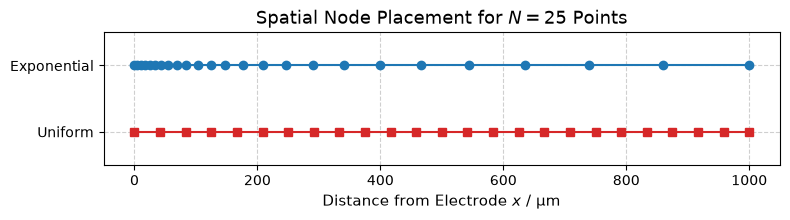

In [2]:
import matplotlib.pyplot as plt
from softpotato.grid import Uniform1DMesh

n_points = 25
x_min, x_max = 0.0, 0.1  # cm (1000 µm)

exp_grid = ExponentialMesh(x_min=x_min, x_max=x_max, n_points=n_points, beta=3.5)
uni_grid = Uniform1DMesh(x_min=x_min, x_max=x_max, n_points=n_points)

print(f"ExponentialMesh: N = {exp_grid.n_points}, dx_min = {exp_grid.dx_min * 1e4:.2f} µm, dx_max = {exp_grid.dx_max * 1e4:.2f} µm")
print(f"Uniform1DMesh:   N = {uni_grid.n_points}, dx_min = {uni_grid.dx_min * 1e4:.2f} µm, dx_max = {uni_grid.dx_max * 1e4:.2f} µm")

plt.figure(figsize=(8, 2.3))
plt.plot(exp_grid.nodes * 1e4, np.ones_like(exp_grid.nodes), "o-", color="#1f77b4", label="ExponentialMesh (beta=3.5)")
plt.plot(uni_grid.nodes * 1e4, np.zeros_like(uni_grid.nodes), "s-", color="#d62728", label="Uniform1DMesh")
plt.yticks([0, 1], ["Uniform", "Exponential"])
plt.ylim(-0.5, 1.5)
plt.xlabel("Distance from Electrode $x$ / µm", fontsize=11)
plt.title(f"Spatial Node Placement for $N = {n_points}$ Points", fontsize=13)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

---

## 3. Comparing Exponential vs. Uniform Grid (Same Number of Points)

To see the impact of grid stretching on numerical accuracy, we solve the same planar diffusion problem on both `exp_grid` and `uni_grid` with `n_points = 25`.

In [3]:
c_bulk = 1.0
t_span = (0.0, 1.0)
t_eval = np.linspace(0.0, 1.0, 101)

# DiffusionProblem on the exponential grid (default planar diffusion)
problem_exp = DiffusionProblem(
    grid=exp_grid,
    diffusivity={"O": D},
    boundary_conditions={"O": (DirichletBC(0.0), NeumannBC(0.0))},
    initial_conditions={"O": c_bulk},
)

# DiffusionProblem on the uniform grid (default planar diffusion)
problem_uni = DiffusionProblem(
    grid=uni_grid,
    diffusivity={"O": D},
    boundary_conditions={"O": (DirichletBC(0.0), NeumannBC(0.0))},
    initial_conditions={"O": c_bulk},
)

solver = get_solver("explicit")
res_exp = solver.solve(problem_exp, t_span=t_span, t_eval=t_eval)
res_uni = solver.solve(problem_uni, t_span=t_span, t_eval=t_eval)

### Concentration Profile at a Specific Time ($t^* = 0.5\text{ s}$)

Below we plot the spatial concentration profile $[O](x, t^*)$ at $t^* = 0.5\text{ s}$ for both grids. Notice how the exponential grid places 13 nodes inside the active diffusion layer ($x < 200\ \mu\text{m}$) to smoothly capture the steep near-wall gradient, whereas the uniform grid only places 5 nodes across the same region.

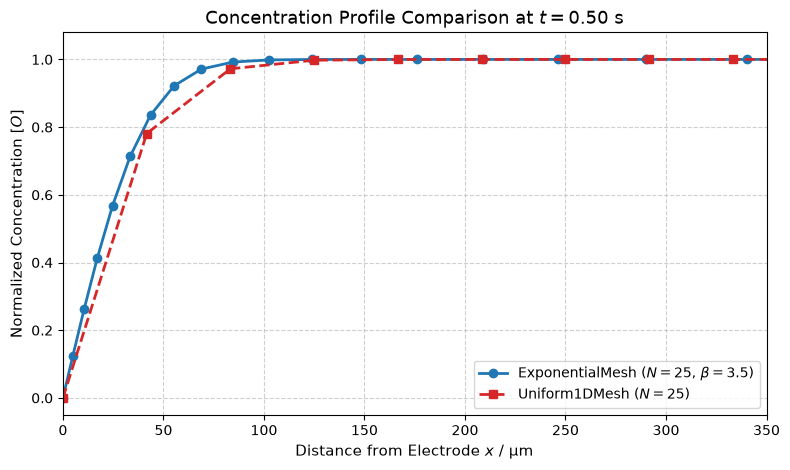

In [4]:
# Target specific time point t = 0.5 s
t_target = 0.5
idx = int(np.argmin(np.abs(res_exp.t - t_target)))
t_actual = res_exp.t[idx]

plt.figure(figsize=(8, 4.8))
plt.plot(
    res_exp.x * 1e4,
    res_exp["O"][idx],
    "o-",
    color="#1f77b4",
    lw=2.0,
    label=f"ExponentialMesh ($N={n_points}$, $\\beta=3.5$)",
)
plt.plot(
    res_uni.x * 1e4,
    res_uni["O"][idx],
    "s--",
    color="#d62728",
    lw=2.0,
    label=f"Uniform1DMesh ($N={n_points}$)",
)

plt.title(f"Concentration Profile Comparison at $t = {t_actual:.2f}$ s", fontsize=13)
plt.xlabel("Distance from Electrode $x$ / µm", fontsize=11)
plt.ylabel("Normalized Concentration $[O]$", fontsize=11)
plt.xlim(0, 350)  # Focus on the active diffusion layer
plt.ylim(-0.05, 1.08)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()

### Faradaic Current Comparison

The Faradaic current is directly proportional to the surface concentration gradient at $x = 0$:

$$I(t) = n F A J(0, t) = -n F A D \left.\frac{\partial [O]}{\partial x}\right\vert_{x=0}$$

At early times, the diffusion layer is very thin. Because `ExponentialMesh` has a much smaller initial step $\Delta x_{\min}$ near the electrode, it accurately resolves the interfacial flux and Faradaic current transient, while the uniform grid with the same number of points significantly underestimates the early-time current.

Relative current error at t = 0.10 s (N = 25 points):
  ExponentialMesh: 5.13%
  Uniform1DMesh:   40.38%


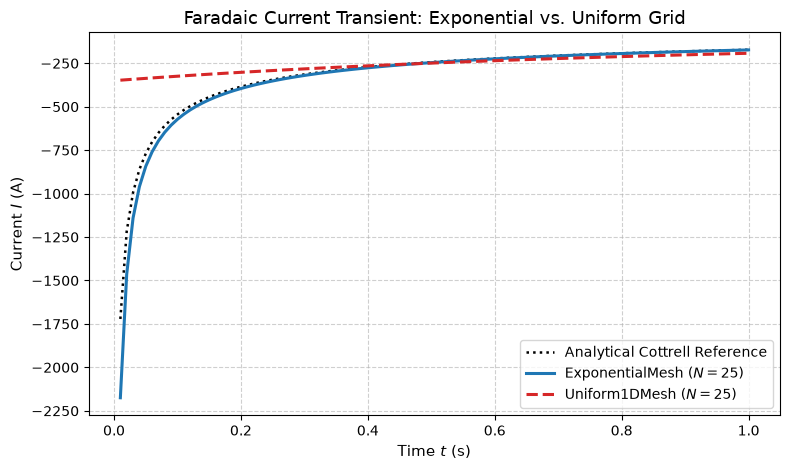

In [5]:
from softpotato.analytical.step import cottrell

# Exclude t = 0 to avoid the initial step singularity
t_trans = res_exp.t[1:]
i_exp = res_exp.currents["O"][1:]
i_uni = res_uni.currents["O"][1:]
i_cottrell = -cottrell(t_trans, n=1, D=D, c_bulk=c_bulk, area=1.0)

# Compare relative current error at t = 0.10 s
idx_early = int(np.argmin(np.abs(t_trans - 0.10)))
err_exp = abs(i_exp[idx_early] - i_cottrell[idx_early]) / abs(i_cottrell[idx_early]) * 100
err_uni = abs(i_uni[idx_early] - i_cottrell[idx_early]) / abs(i_cottrell[idx_early]) * 100
print(f"Relative current error at t = {t_trans[idx_early]:.2f} s (N = {n_points} points):")
print(f"  ExponentialMesh: {err_exp:.2f}%")
print(f"  Uniform1DMesh:   {err_uni:.2f}%")

plt.figure(figsize=(8, 4.8))
plt.plot(t_trans, i_cottrell, "k:", lw=1.8, label="Analytical Cottrell Reference")
plt.plot(t_trans, i_exp, "-", color="#1f77b4", lw=2.2, label=f"ExponentialMesh ($N={n_points}$)")
plt.plot(t_trans, i_uni, "--", color="#d62728", lw=2.2, label=f"Uniform1DMesh ($N={n_points}$)")

plt.title("Faradaic Current Transient: Exponential vs. Uniform Grid", fontsize=13)
plt.xlabel("Time $t$ (s)", fontsize=11)
plt.ylabel("Current $I$ (A)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

---

## 4. Summary

| Step | Action | Soft Potato API |
| :--- | :--- | :--- |
| **1. Exponential Grid** | Cluster nodes near the electrode ($x = x_{\min}$) | `ExponentialMesh(x_min, x_max, n_points, beta)` |
| **2. Uniform Grid** | Space nodes evenly across $[x_{\min}, x_{\max}]$ | `Uniform1DMesh(x_min, x_max, n_points)` |
| **3. Problem Setup** | Pass the mesh to `DiffusionProblem` (planar by default) | `DiffusionProblem(grid=exp_grid, diffusivity=..., ...)` |
| **4. Solve & Compare** | Integrate the PDE and extract profiles & currents | `result["O"]`, `result.currents["O"]` |

For more information on the `grid` module visit [`softpotato.grid`](/api/grid/).